# Analisis de placa radiocromica

Analisis de imagen para la placa radiocromica irradiada en el servicio de radioterapia de AUNA por un acelerador lineal cualesquiera.

El objetivo es detectar 5 puntos en la imagen, unir los puntos, trazar un cuadrado y hacer las siguientes mediciones:

- El FWHM cross-plane e in-plane.
- El desfase del cuadrado trazado respecto a los bordes del perfil al nivel de FWHM. (Para esto se podria usar el trazado de puntos, dibujar la linea, identificar el pixel en la region central, trazar los perfiles cross-plane e in-plane y segun este pixel fijar un posicion en este perfil y definir la posicion respecto a este punto en la curva con el pixel de referencia, definir la distancia entre los pixeles y hacer la conversion a longitud.)

In [2]:
import sys

print(sys.executable)
print(sys.version)

/home/felipepp/Documents/CodigosPython/Codigo_AnalisisImagen/.venv/bin/python
3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]


## Librerias

In [3]:
import numpy as np
import scipy as sp
from scipy.fft import fft2
from scipy.fft import ifft2
from scipy.fft import fftfreq
from scipy.fft import fftshift, ifftshift
from scipy.signal import convolve2d

import imageio

import os
import cv2
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import animation
from matplotlib.animation import PillowWriter
import pint

from PIL import Image

u = pint.UnitRegistry()

### Funciones auxiliares

In [4]:
def normalize_image(image):
    normalized_image = (image - np.min(image)) / (np.max(image) - np.min(image))
    return normalized_image

def intensidad_del_campo(campo):
    intensidad_espectro_imagen = np.abs(campo)**2
    return intensidad_espectro_imagen

## Operaciones iniciales con la imagen

En caso de que sea mejor usar una imagen .TIF y con el flag de unchanged de cv2.imread() hay que decirle a claude que lo tenga en cuenta y que ajuste eso al de braqui tambien.

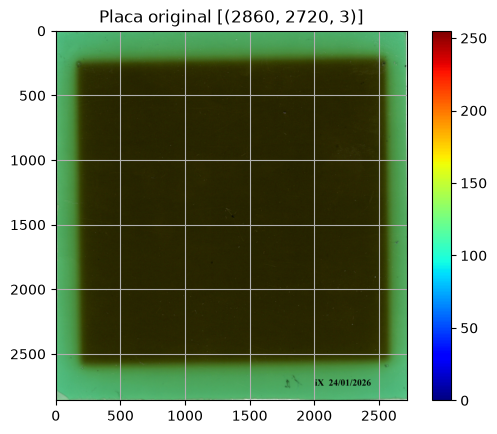

In [5]:
ruta_imagen = '/home/felipepp/Documents/CodigosPython/ImagenesDeReferencia/PlacasHistoricas/EPSON001.TIF'

placa_analizada = cv2.imread(ruta_imagen, 1)
placa_analizada_gray = cv2.bitwise_not(cv2.imread(ruta_imagen, 0))

plt.imshow(placa_analizada, cmap = 'jet')
plt.title(f"Placa original [{np.shape(placa_analizada)}]")
plt.colorbar()
plt.grid()
plt.show()

In [6]:
tamano_pixel = 25.4/600 # Escaneado a 600 dpi, tamaño de pixel en mm

## Ubicacion manual de los puntos de referencia

A partir de las esquinas del campo luminoso que se proyecta sobre la placa y el centro del crosshair del acelerador se hacen unas marcas sobre la pelicula radiocromica, en esta parte lo unico que haremos es identificar manualmente la posicion para descargarle responsabilidad al proceso automatico y bajar la dificultad de construir un umbral que automaticamente identifique las coordenadas de estos puntos.

QFontDatabase: Cannot find font directory /home/felipepp/Documents/CodigosPython/Codigo_AnalisisImagen/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/felipepp/Documents/CodigosPython/Codigo_AnalisisImagen/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/felipepp/Documents/CodigosPython/Codigo_AnalisisImagen/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/felipepp/Documents/CodigosPython/Codigo_AnalisisImagen/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no long

Puntos guardados (coordenadas [x, y]): [(177, 259), (2542, 250), (1375, 1442), (207, 2609), (2568, 2592)]


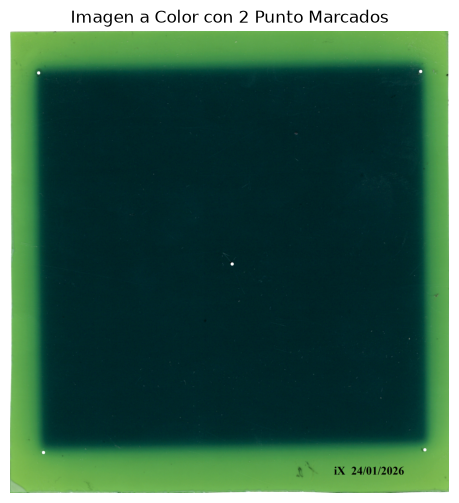

In [7]:
# --- 1. Aplicar mapa de color a la imagen base ---
# Convertimos el float32 [0.0, 1.0] a uint8 [0, 255] para aplicar el mapa de color de OpenCV
img_uint8 = (placa_analizada).clip(0, 255).astype(np.uint8)

# Aplicar mapa de color (Puedes cambiar cv2.COLORMAP_JET por:
# COLORMAP_VIRIDIS, COLORMAP_HOT, COLORMAP_TURBO, COLORMAP_PLASMA, COLORMAP_BONE)
# placa_color_bgr = cv2.applyColorMap(img_uint8, cv2.COLORMAP_JET)

# Convertir de vuelta a float32 [0.0, 1.0] para trabajar uniformemente
placa_color = img_uint8.astype(np.float32) / 255.0

puntos = []

def seleccionar_puntos(event, x, y, flags, param):
    global puntos, placa_color

    if event == cv2.EVENT_LBUTTONDOWN and len(puntos) < 5:
        puntos.append((x, y))

        # Dibujar punto con intensidad de contraste sobre el mapa de calor
        # (1.0, 1.0, 1.0) = Blanco puro | (0.0, 0.0, 0.0) = Negro puro
        cv2.circle(placa_color, (x, y), 10, (1.0, 1.0, 1.0), -1)


# --- 2. Interfaz interactiva OpenCV ---
cv2.namedWindow("Seleccionar 5 Puntos", cv2.WINDOW_NORMAL)
cv2.setMouseCallback("Seleccionar 5 Puntos", seleccionar_puntos)
cv2.resizeWindow("Seleccionar 5 Puntos", 1280, 720)

while True:
    cv2.imshow("Seleccionar 5 Puntos", placa_color)

    key = cv2.waitKey(1) & 0xFF
    if key == 27 or len(puntos) == 5:
        if len(puntos) == 5:
            cv2.imshow("Seleccionar 5 Punto", placa_color)
            cv2.waitKey(300)
        break

cv2.destroyAllWindows()
cv2.waitKey(1)

# --- 3. Renderizado inline dentro del Notebook ---
print(f"Puntos guardados (coordenadas [x, y]): {puntos}")

# Convertir BGR a RGB para mostrar exactamente lo mismo en Matplotlib
placa_color_rgb = cv2.cvtColor(
    (placa_color * 255).astype(np.uint8), cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 6))
plt.imshow(placa_color_rgb)
plt.title("Imagen a Color con 2 Punto Marcados")
plt.axis("off")
plt.show()

plt.imsave('/home/felipepp/Documents/CodigosPython/ImagenesDeReferencia/Placas_codigo/placa_0.jpeg', placa_color_rgb)

Identificamos los puntos asumiendo una localizacion por cuadrantes.

In [8]:
for i in puntos: # Podemos dejar el ancho de la region central tambien como una variable expuesta la usuario
    if  (int(np.shape(placa_analizada)[0]//2) - 100) < int(i[0]) < (int(np.shape(placa_analizada)[0]//2) + 100) and (int(np.shape(placa_analizada)[1]//2) - 100) < int(i[1]) < (int(np.shape(placa_analizada)[1]//2) + 100):
        punto_CC_0 = i
    else:
        if int(i[0]) < int(np.shape(placa_analizada)[0]//2):
            # Region horizontal a la izquiera
            if int(i[1]) > int(np.shape(placa_analizada)[1]//2):
                punto_DL_0 = i
            else:
                punto_UL_0 = i
        else:
            # Region horizontal a la derecha
            if int(i[1]) > int(np.shape(placa_analizada)[1]//2):
                punto_DR_0  = i
            else:
                punto_UR_0 = i

print(f"Coordenada arriba izquierda: {punto_UL_0}")
print(f"Coordenada arriba derecha: {punto_UR_0}")
print(f"Coordenada abajo izquierda: {punto_DL_0}")
print(f"Coordenada abajo derecha: {punto_DR_0}")
print(f"Coordenada punto central {punto_CC_0}")

Coordenada arriba izquierda: (177, 259)
Coordenada arriba derecha: (2542, 250)
Coordenada abajo izquierda: (207, 2609)
Coordenada abajo derecha: (2568, 2592)
Coordenada punto central (1375, 1442)


Haremos el trazado de lo que corresponde idealmente al campo luminoso, aqui no es necesario hacerlo sobre la imagen, pues solo necesitamos visualizar la forma del campo luminoso y hacer operaciones con los puntos identificados, que son solo coordenadas sobre una imagen:

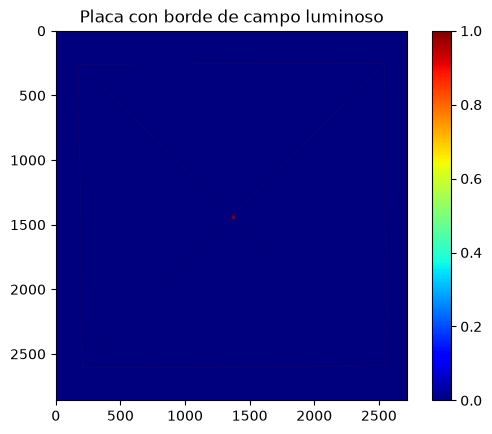

In [9]:
fondo = np.zeros(np.shape(placa_analizada_gray))

valor_trazos = 1
grosor_trazo = 1

cv2.line(fondo, punto_UL_0, punto_UR_0, valor_trazos, grosor_trazo)
cv2.line(fondo, punto_UL_0, punto_DL_0, valor_trazos, grosor_trazo)
cv2.line(fondo, punto_UL_0, punto_DR_0, valor_trazos, grosor_trazo)
cv2.line(fondo, punto_DL_0, punto_UR_0, valor_trazos, grosor_trazo)
cv2.line(fondo, punto_UR_0, punto_DR_0, valor_trazos, grosor_trazo)
cv2.line(fondo, punto_DL_0, punto_DR_0, valor_trazos, grosor_trazo)

# cv2.circle(fondo, (int(np.round(x_0, 0)), int(np.round(y_0, 0))), 15, color = 1, thickness = -1)
cv2.circle(fondo, punto_CC_0, 15, color = 1, thickness = -1)

plt.imshow(fondo, cmap = 'jet')
plt.title("Placa con borde de campo luminoso")
plt.colorbar()
plt.show()

Ahora con esta informacion podemos ajustar la inclinacion de la imagen en caso de que esta este torcida respecto a la vertical de mi eje.

### Extraccion del angulo

Utilizaremos el angulo de las diagonales para alinear correctamente el rectangulo respecto a la vertical de mi imagen, que se traza desde las esquinas del campo luminoso.

In [10]:
tetha_0 =  45 - 1 * np.degrees(np.arctan((punto_UL_0[0] - punto_DR_0[0])/(punto_UL_0[1] - punto_DR_0[1])))
print(f"Diagonal tetha_0: {tetha_0}")

tetha_1 =  45 + 1 * np.degrees(np.arctan((punto_UR_0[0] - punto_DL_0[0])/(punto_UR_0[1] - punto_DL_0[1])))
print(f"Diagonal tetha_1: {tetha_1}")

mean_tetha = (tetha_0 - tetha_1) / 2

# mean_tetha = (tetha_0 + tetha_1)/2
print(f"Diagonal mean_tetha: {mean_tetha}")

Diagonal tetha_0: -0.7034268091506561
Diagonal tetha_1: 0.29294561694943866
Diagonal mean_tetha: -0.4981862130500474


Ahora segun el angulo medio medido debemos rotar la imagen con operaciones matriciales el angulo opuesto al que se calcula. Sin embargo, aparte del angulo necesitamos el centro de rotacion, y ya que estamos usando directamente las diagonales, tomaremos como centro de rotacion la interseccion entre estas calculado con el metodo de interseccion entre rectas.

In [11]:
# Puntos diagonal 1: Arriba izquierda y abajo derecha
# Pendiente diagonal 1:
m_1 = (punto_DR_0[1] - punto_UL_0[1])/(punto_DR_0[0] - punto_UL_0[0])

# Puntos diagonal 2: Arriba derecha y abajo izquierda
# Pendiente diagonale 2:
m_2 = (punto_UR_0[1] - punto_DL_0[1])/(punto_UR_0[0] - punto_DL_0[0])

# Puntos de interseccion de cada diagonal con el eje y
b_1 = punto_DR_0[1] - punto_DR_0[0] * m_1
b_2 = punto_UR_0[1] - punto_UR_0[0] * m_2

x_0 = (b_2 - b_1)/(m_1 - m_2) # Resolviendo igualando las rectas en y

y_0 = m_1 * x_0 + b_1 # Punto en y para el valor de x hallado

cc_diagonales = (int(np.round(x_0, 0)), int(np.round(y_0, 0)))

print(f"El punto de interseccion de las rectas esta en: {cc_diagonales}")

El punto de interseccion de las rectas esta en: (1376, 1428)


El centro de rotacion no cambia de posicion luego de la transformacion, en este caso nuestro centro de rotacion por orden de Adriana va a ser el de la interseccion de las diagonales. Sin embargo, todos los demas puntos cambian de posicion segun la rotacion de la matriz de la imagen, es imperativo entonces predecir la posicion resultante de estos puntos.

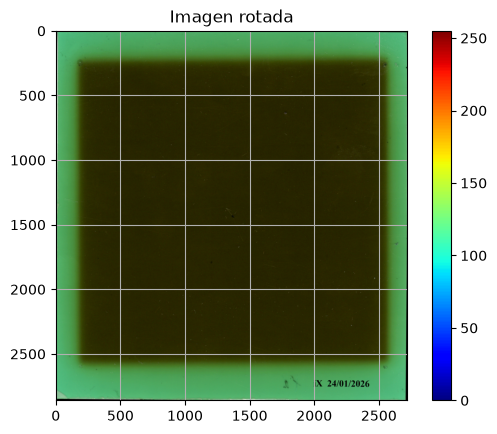

In [12]:
centro_rotacion = cc_diagonales

placa_matriz_transformacion = cv2.getRotationMatrix2D(
    centro_rotacion,
    mean_tetha, 1)

placa_rotada = cv2.warpAffine(placa_analizada, 
                               placa_matriz_transformacion, 
                               (np.shape(placa_analizada)[1], np.shape(placa_analizada)[0]))

plt.imshow(placa_rotada, cmap = 'jet')
plt.title('Imagen rotada')
plt.colorbar()
plt.grid()
plt.show()

Ahora debemos encontrar las nuevas posiciones de los puntos rotados.

In [13]:
puntos

[(177, 259), (2542, 250), (1375, 1442), (207, 2609), (2568, 2592)]

In [14]:
arr_puntos = np.array(puntos)

puntos_rotados_tetha = cv2.transform(
    arr_puntos.reshape(-1, 1, 2),
    placa_matriz_transformacion
)

puntos_rotados_tetha = puntos_rotados_tetha.reshape(-1, 2).tolist()

print(f"Nueva posicion puntos de referencia: {puntos_rotados_tetha}")

Nueva posicion puntos de referencia: [[187, 249], [2552, 260], [1375, 1442], [197, 2599], [2558, 2602]]


Es importante tener en cuenta que no quedara perfectamente vertical, debido a que el tetha medio no es igual a el desfase en inclinacion respecto a los 45 grados de ninguna de las dos diagonales, por lo cual el ajuste NO alinea con respecto a 45 grados a ninguna de las diagonales.

Volvamos a sacar entonces las posiciones de cada uno de los puntos, con las nuevas coordenadas logicamente.

In [15]:
for i in puntos_rotados_tetha: # Podemos dejar el ancho de la region central tambien como una variable expuesta la usuario
    if  (int(np.shape(placa_analizada)[0]//2) - 100) < int(i[0]) < (int(np.shape(placa_analizada)[0]//2) + 100) and (int(np.shape(placa_analizada)[1]//2) - 100) < int(i[1]) < (int(np.shape(placa_analizada)[1]//2) + 100):
        punto_CC = i
    else:
        if int(i[0]) < int(np.shape(placa_analizada)[0]//2):
            # Region horizontal a la izquiera
            if int(i[1]) > int(np.shape(placa_analizada)[1]//2):
                punto_DL = i
            else:
                punto_UL = i
        else:
            # Region horizontal a la derecha
            if int(i[1]) > int(np.shape(placa_analizada)[1]//2):
                punto_DR = i
            else:
                punto_UR = i

print(f"Coordenada arriba izquierda: {punto_UL}")
print(f"Coordenada arriba derecha: {punto_UR}")
print(f"Coordenada abajo izquierda: {punto_DL}")
print(f"Coordenada abajo derecha: {punto_DR}")
print(f"Coordenada punto central {punto_CC}")

# Ahora debemos calcular la distancia por coordenada:
desfase_cx = (punto_CC[0] - x_0) * tamano_pixel
desfase_cy = (punto_CC[1] - y_0) * tamano_pixel

print(f"Desfase de centro en crossplane: {np.round(desfase_cx, 3)} mm")
print(f"Desfase de centro en inplane: {np.round(desfase_cy, 3)} mm")

Coordenada arriba izquierda: [187, 249]
Coordenada arriba derecha: [2552, 260]
Coordenada abajo izquierda: [197, 2599]
Coordenada abajo derecha: [2558, 2602]
Coordenada punto central [1375, 1442]
Desfase de centro en crossplane: -0.022 mm
Desfase de centro en inplane: 0.573 mm


Estos puntos solo se tienen que sacar una vez porque la posicion no cambia, ni deberia ni por capas de color ni escala de grises, obvio mucho menos cuando se hace el simple trazado de las lineas de campo luminoso sobre un fondo cero.

## Separacion por capas de color de la imagen

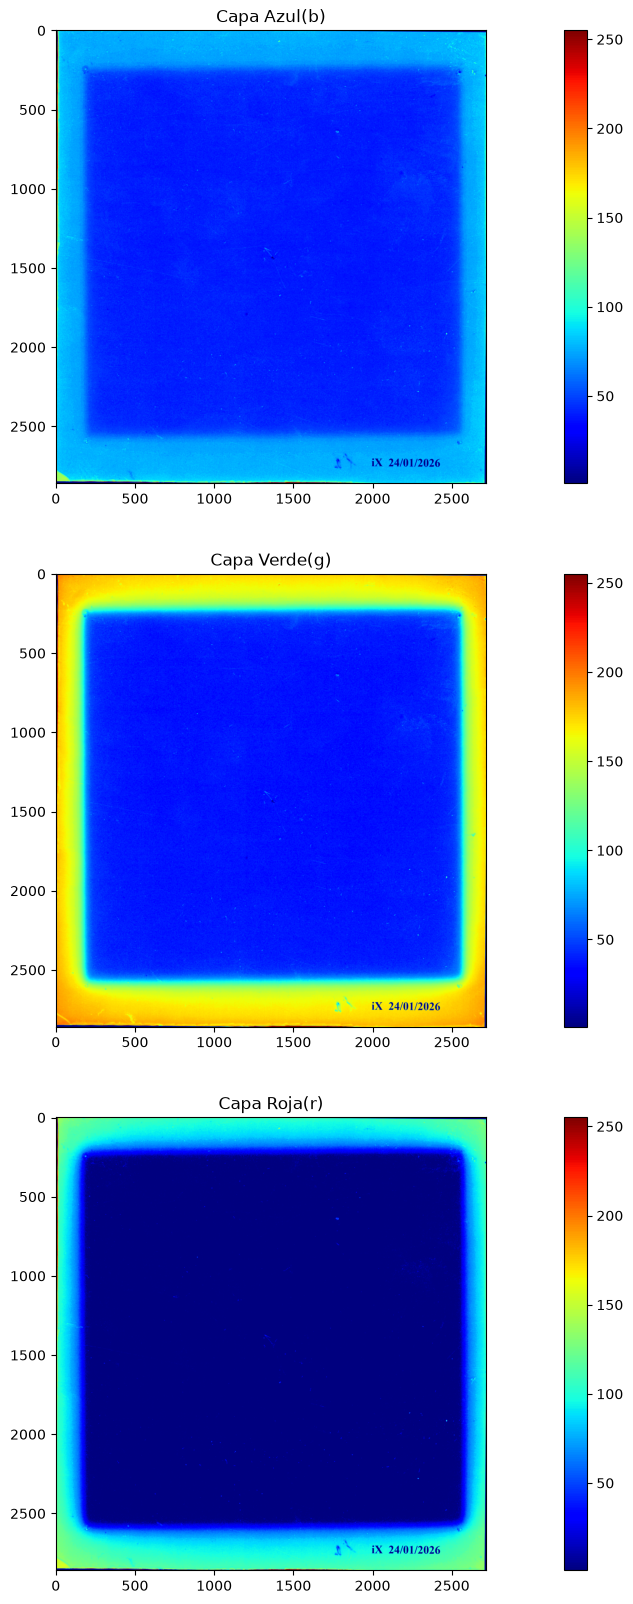

In [16]:
b, g, r = cv2.split(placa_rotada) # Sacado directamente de geeksforgeeks

b = np.where(
    b <= 0,
    1,
    b
)

g = np.where(
    g <= 0,
    1,
    g
)

r = np.where(
    r <= 0,
    1,
    r
)

plt.figure(figsize = (20, 20))

plt.subplot(3, 1, 1)
plt.imshow(b, cmap = 'jet')
plt.colorbar()
plt.title('Capa Azul(b)')

plt.subplot(3, 1, 2)
plt.imshow(g, cmap = 'jet')
plt.colorbar()
plt.title('Capa Verde(g)')

plt.subplot(3, 1, 3) # Numero filas, columnas, posicion especifica.
plt.imshow(r, cmap = 'jet')
plt.colorbar()
plt.title('Capa Roja(r)')

plt.show()

## Placa virgen

Se escanea una pelicula ebt3 virgen (sin irradiar) para fijar el piso y definir la densidad optica para cada canal, esto nos permite relacionar mucho mas directamente el valor de intensidad con el valor de dosis. Eventualmente dudaremos si es necesario usar la capa azul para eliminar defectos, dado que parece que es la capa que mas luz deja pasar, menos saturada, facilita la muestra de defectos. Pero puede que importe es realmente hacer un balance real entre los resultados de ese articulo y el nuestro pues la polimerizacion depende tambien del area de la pelicula, porque dos peliculas con la misma dosis pero un cuarto del area superficial no pueden sufrir el mismo nivel de polimerizacion a no ser de que ambas alcancen saturacion. Debemos aplicar los rois para definir uniformidad y ruido similar a las pruebas del DICOM de CatPhan y con esto podemos definir un piso confiable para cada capa RGB y al mismo tiempo dejar un analisis de cada lote de peliculas radiocromicas ebt3.

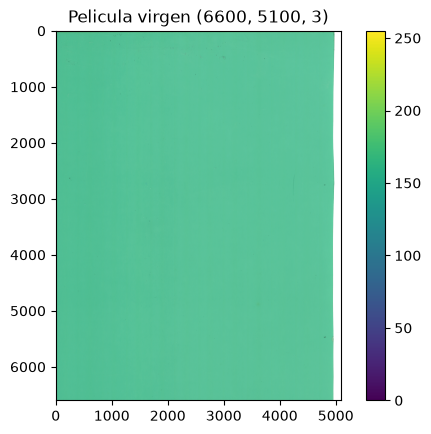

In [17]:
pelicula_virgen = cv2.imread('/home/felipepp/Documents/CodigosPython/ImagenesDeReferencia/PlacasHistoricas/EPSON179.TIF', 1)

plt.imshow(pelicula_virgen)
plt.title(f"Pelicula virgen {np.shape(pelicula_virgen)}")
plt.colorbar()
plt.show() 

In [18]:
np.shape(pelicula_virgen)

(6600, 5100, 3)

In [19]:
pelicula_virgen[6599][5099]

array([255, 255, 255], dtype=uint8)

In [20]:
b_v, g_v, r_v = cv2.split(pelicula_virgen)

# b_v = np.array(b_v)
# g_v = np.array(g_v)
# r_v = np.array(r_v)

forma_virgen = np.shape(pelicula_virgen)
print(forma_virgen)

piso_b = np.mean(b_v[
    forma_virgen[0]//2 - 20: forma_virgen[0]//2 + 20,
    forma_virgen[1]//2 - 20: forma_virgen[1]//2 + 20
])

piso_g = np.mean(g_v[
    forma_virgen[0]//2 - 20: forma_virgen[0]//2 + 20,
    forma_virgen[1]//2 - 20: forma_virgen[1]//2 + 20
])

piso_r = np.mean(r_v[
    forma_virgen[0]//2 - 20: forma_virgen[0]//2 + 20,
    forma_virgen[1]//2 - 20: forma_virgen[1]//2 + 20
])

(6600, 5100, 3)


Para estas graficas hemos preferido utilizar la imagen cruda y dejar la de los puntos solo para tener las coordenadas de los puntos y definir el cuadrado del campo luminoso y alinear la imagen, esencialmente esa es su unica funcion. La imagen cruda nos permite tener solo los niveles de ruido naturales de la prueba, no inducidos aqui por el analisis que llevemos a cabo.

El marco realmente era util para elegir mas facilmente el punto donde ibamos a escoger el valor de la pelicula virgen, el problema es que como el espectro es mas anchos sobre los perfiles que atraviesan el centro entonces el marco recorta parte de ellos, si no ponemos el marco pero elegimos el valor de la pelicula virgen ignorando un grosor equivalente al del marco como si estuviera, podemos obtener le mismo valor de la pelicula virgen sin recortar innecesariamente el borde.

In [21]:
valor_pelicula_b = piso_b
print(f"Valor de centro blue: {valor_pelicula_b}")

valor_pelicula_g = piso_g
print(f"Valor de centro green: {valor_pelicula_g}")

valor_pelicula_r = piso_r
print(f"Valor de centro red: {valor_pelicula_r}")

Valor de centro blue: 88.4425
Valor de centro green: 195.05
Valor de centro red: 152.6025


Este analisis luego se puede mejorar con lo de extraer 4 datos, uno de cada esquina, talvez mas, y sacar la mediana para encontrar el valor de la pelicula, que precauciones se tienen para garantizar que al menos un valor de las 4 esquinas o los cuatro tienen selectores que caen realemnte en una zona que corresponde a la pelicula virgen y no que, por ejemplo por la rotacion todos esos puntos quedan en el vacio.

## Acondicionamiento de la imagen

Cuanto nos vamos a separar del marco a acercar a la penumbra?:

In [22]:
np.shape(b)

(2860, 2720)

Mientras no de cero es logico que no estamos en la region dentro del marco que es igual a cero en toda la escala de color de cada capa.

In [23]:
len(np.where(b >= valor_pelicula_b))

2

In [24]:
int(valor_pelicula_b)

88

## Importante

Si el valor de pelicula virgen que se escoge cae en cero, pues logicamente nada va a cambiar, la intencion es ajustar borde segun el valor de la pelicula asi que el marco debe ser suficientemente grueso como para cubrir las regiones vacias de la imagen, talvez en proporcion al angulo rotado, para que el valor que se escoge un pixel hacia adentro en cada direccion sea el de la pelicula y no el del vacio.

Con la estructura que teniamos si simplemente metemos la formula de la densidad optica nos queda invertido el perfil, esto seguro por la naturaleza de la operacion. Por lo cual podemos hacer las operaciones con la imagen cruda, pero aqui surge una duda, para la que podemos hacer pruebas y comprobar y es, deberiamos estandarizar el piso antes o despues de aplicar lo de la densidad optica?

Ley de Beer-Lambert para convertir la distribucion de intensidad luminosa en densidad optica, usando el valor de intensidad de la pelicula virgen de cada capa de color RGB, y su razon con la matriz de la placa restringiendo valores por encima del valor de la pelicula virgen, para eliminar ruidos y acondicionar la imagen, pues valores de mayor intensidad luminosa corresponden al fondo del escaner, pues la pelicula deberia ser el valor maximo en intensidad de luz. La imagen de la placa realmente representa un perfil de valle, hacia abajo en el centro, pues indica es cuanta luz logra pasar, y como la zona central se opaca pues por ahi logicamente pasa menos luz, ahora, cuando hacemos la conversion a densidad optica, sin invertir artificialmente ninguna imagen, este ya adopta su forma hacia arriba, pasando de valle a meseta, pues ahora lo que representa es que tan opaco es, no que tanta luz deja pasar, lo contrario, vemos que la imagen roja satura, pero como se cortan todos los valores menores o iguales a cero para evitar que se vaya para infinito, el valor maximo queda cerca de log10(1)

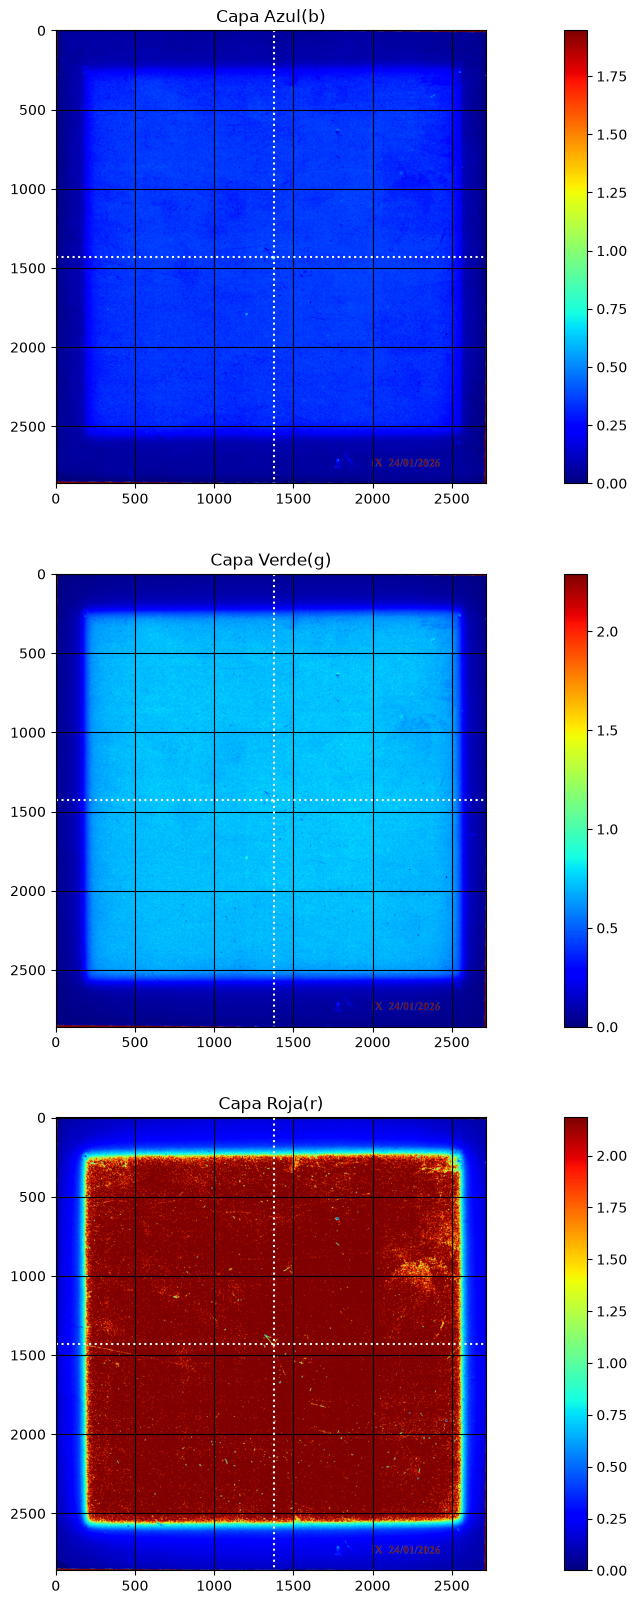

In [25]:
placa_recorte_borde_b = np.log10(
    valor_pelicula_b
    /
    np.where(
        b >= valor_pelicula_b,
        valor_pelicula_b,
        b
    )
)

placa_recorte_borde_g = np.log10(
    valor_pelicula_g
    /
    np.where(
        g >= valor_pelicula_g,
        valor_pelicula_g,
        g
    )
)

placa_recorte_borde_r = np.log10(
    valor_pelicula_r
    /
    np.where(
        r >= valor_pelicula_r,
        valor_pelicula_r,
        r
    )
)


plt.figure(figsize = (20, 20))

plt.subplot(3, 1, 1)
plt.imshow(placa_recorte_borde_b, cmap = 'jet')
plt.vlines(centro_rotacion[0], 0,
           np.shape(placa_recorte_borde_b)[0] - 1,
           colors = 'white', linestyles = ':')
plt.hlines(centro_rotacion[1], 0,
           np.shape(placa_recorte_borde_b)[1] - 1,
           colors = 'white', linestyles = ':')
plt.colorbar()
plt.grid(True, color = 'black')
plt.title('Capa Azul(b)')

plt.subplot(3, 1, 2)
plt.imshow(placa_recorte_borde_g, cmap = 'jet')
plt.vlines(centro_rotacion[0], 0,
           np.shape(placa_recorte_borde_g)[0] - 1,
           colors = 'white', linestyles = ':')
plt.hlines(centro_rotacion[1], 0,
           np.shape(placa_recorte_borde_g)[1] - 1,
           colors = 'white', linestyles = ':')
plt.colorbar()
plt.grid(True, color = 'black')
plt.title('Capa Verde(g)')

plt.subplot(3, 1, 3)
plt.imshow(placa_recorte_borde_r, cmap = 'jet')
plt.vlines(centro_rotacion[0], 0,
           np.shape(placa_recorte_borde_r)[0] - 1,
           colors = 'white', linestyles = ':')
plt.hlines(centro_rotacion[1], 0,
           np.shape(placa_recorte_borde_r)[1] - 1,
           colors = 'white', linestyles = ':')

plt.colorbar()
plt.grid(True, color = 'black')
plt.title('Capa Roja(r)')

plt.show()

Muy importante notar que aunque ya no aparecen los pixeles maximos de la capa roja en infinito esto no signigica que sean pixeles validos y por tanto el techo esta levemente indefinido, lo que desencadena desconfianza en el analizas a partir de las medidas dependientes del valor medio de la meseta y forzan a descartar la capa roja del analisis debido a la saturacion, la polimerizacion que sufre la pelicula no deja pasar luz roja, por lo que la densidad optica en esta capa es fisicamente infinita.

Sin embargo creo que hace falta algo bastante util y es que ademas de la normalizacion debemos es normalizar respecto a el valor de la pelicula virgen, pero realmente hay alguna diferencia? ... Si dejo solo el marco y normalizo.. siento que no es lo mismo, probemos algo:

## Perfiles crossplane e inplane

In [26]:
cc_diagonales == punto_CC

False

In [27]:
np.shape(placa_recorte_borde_r)

(2860, 2720)

In [28]:
np.shape(placa_recorte_borde_r)[1] - centro_rotacion[0]

1344

Bueno, dado que el proceso de filtrado es un poco diferente, porque aqui si es importante la altura absoluta y no solo la relativa, pues debemos encontrar la altura media, por lo tanto se vuelve sumamente importante definir adecuadamente el nivel de piso, y no solo dejar el nivel de cero como el menor y no saber que valores intermedios hay y mas aun, que valor dentro de la escala normalizada corresponde al de la pelicula virgen. Y por lo tanto es que es diferente la seleccion de los intervalos para la grafica, porque despues de ese acondicionamiento podemos y debemos trabajar en todo el rango de la imagen.

De la misma forma que en el primer analisis debemos obtener la media de la meseta ignorando la zona central contaminada por el punto de marcacion. Posteriormente haremos un barrido similar al de braquiterapia para encontrar una media sobre el resto de la region.

Aparece un problema al eliminar los ceros de las periferias y escoger el siguiente valor, pues para eliminarlos lo que se esta haciendo es encontrarlos primero con un where y luego extraer el intervalo util ignorando esa seccion de cero asumiendo que es continua, es por esto que si por alguna razon hay un valor cero en el interior de la meseta, el algoritmo lo va a encontrar y va a iniciar la graficacion y el analisis desde ese valor en adelante, logicamente el problema es que recorta informacion util de la curva e inicia en un punto aleatorio posiblemente debido a ruido fotonico pero eliminando porciones vitales del perfil. Lo que se puede hacer entonces es solo tener en cuenta los ceros que se van a eliminar si estos estan fuera de la meseta, de la misma forma que solo se tiene en cuenta lo que esta dentro de la meseta para el calculo de la media.

In [29]:
extremo_meseta = 1000

excepcion_centro = 100

# utol_min = 0.1

Nos quedamos con el pergil completo, sin recortar por bordes ni nada, lo unico que hemos hecho es rellenar los vacios fuera de la placa con el valor de la pelicula, como sabemos esto? Pues porque en la funcion where se reemplazan solo los valores menores que la pelicula virgen por el valor de la pelicual virgen, los unicos valores menores son los vacios de la placa frente al escaneo, asi que lo unico que recorta los perfiles son la frontera fisica de la placa, no porque ahi exista un marco.

Vamos a probar implementando ese metodo de quedarnos con el segundo minimo entre los dos extremos para crear un piso mas confiable y automatizado en los perfiles, el problema tiene que ver con la eficiencia del codigo, porque eso se distingue facilmente una vez tenemos el perfil ya con los valores menores o iguales a cero por fuera del intervalo de interes, pero antes de esto como encontramos ese minimo, por definicion ese minimo por cada lado viene por el minimo diferente de cero. Esto no lo vamos a hacer por que es recortar y modificar el perfil solo para mejorar la forma del perfil.

Vamos a mejorar el metodo de encontrar el corte recorriendo ese intervalo del arreglo en reversa.

In [30]:
a = np.array([1,2,3,4,5,6,7,8,9,9,8,7,4,5,6,1,2,3])
b = np.array([1,5,9])
print(a[b], type(b))

[2 6 9] <class 'numpy.ndarray'>


In [31]:
def encontrar_interseccion_HM(array, medium_high):

    tol_range = 25/100

    array = np.array(array)

    group_inter = np.where(
        (array >= (1 - tol_range) * medium_high) & (array <= (1 + tol_range) * medium_high)
    )[0]

    corte_crudo = np.abs(
        array[group_inter] - medium_high
    ).argmin()

    corte_ajustado = group_inter[corte_crudo]
    
    return corte_ajustado


# Necesitamos un algortimo capaz de ajustarse automaticamente al
# rango que contiene realmente el punto de corte con la altura media
# pues la primer tolerancia ayuda a hacer lo que la otra no puede sola
# y es a esa otra que debemos ayudar, a identificar el rango 
# apropiadanmente, es claro que necesitamos separar el rango de los
# puntos mas cercanos entre si son mas grades o mas pequenos de lo que deberian

# Los puntos que corresponden a la parte baja de la penumbra simplemente
# tienen una posicion de pixel relativamente muy inferiror a la que tendra la posicion
# del punto de corte a la media altura. Sin embargo, la dificultad como siempre es el ruido
# para esto podemos..., un filtro de mediana? Si funciona bien nos podria solucionar este problema
    # completamente, idealmente.

from scipy.signal import medfilt

def filtro_mediana(array):

    return medfilt(array, kernel_size = 3)

Algo muy importante para notar aqui es que cuando vamos a eliminar los valores que se alejan de la zona de interes, que corresponde a la que consideramos ideal, para el valor de donde realmente debe ir el corte, pues si elegimos comparar una media cabe la posibilidad de que este valor debido a la naturalea aleatoria del tipo y distribucion de los valores que pueden aparecer ahi  termine eliminando el valor correcto o mas cercano al punto que esperamos, por lo cual hay que definir un rango de escala fijo, curisoamente el concepto de definir un marco ayuda mucho, sin que esto sea excluyente de entender que la imagen se debe analizar totalmente, por lo cual otra vez concluimos que agregar un borde es util solo al momento de tomar medidas, no una modificacion previa y permanente de la imagen que se va a analizar.

In [32]:
np.shape(placa_recorte_borde_b)

(2860, 2720)

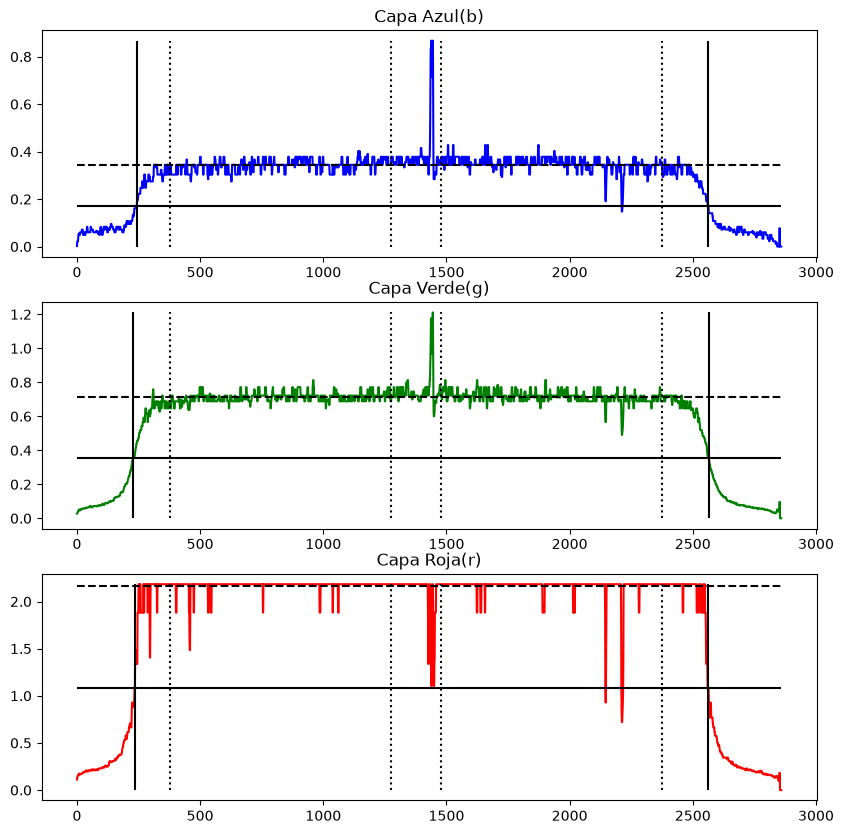

Media inplane blue: 0.3446268074648864
Media inplane green: 0.7138517001621809
Media inplane red: 2.1642484192340703
HM inplane blue: 0.1723134037324432
HM inplane green: 0.35692585008109046
HM inplane red: 1.0821242096170351


In [33]:
b_inplane = np.rot90(placa_recorte_borde_b)[
    np.shape(placa_recorte_borde_b)[1] - centro_rotacion[0]
]

g_inplane = np.rot90(placa_recorte_borde_g)[
    np.shape(placa_recorte_borde_g)[1] - centro_rotacion[0]
]

r_inplane = np.rot90(placa_recorte_borde_r)[
    np.shape(placa_recorte_borde_r)[1] - centro_rotacion[0]
]

b_inplane = filtro_mediana(b_inplane)
g_inplane = filtro_mediana(g_inplane)
r_inplane = filtro_mediana(r_inplane)


# Ese es el array del corte inplane, crudo. No se debe modificar mas
# hay que es hacer el analisis a partir de estos datos

media_inplane_b = (np.mean(
    b_inplane[
        centro_rotacion[0] - extremo_meseta
        :
        centro_rotacion[0] - excepcion_centro
        ]) + np.mean(b_inplane[
            centro_rotacion[0] + excepcion_centro
            :
            centro_rotacion[0] + extremo_meseta
            ])
) * 0.5

media_inplane_g = (np.mean(
    g_inplane[
        centro_rotacion[0] - extremo_meseta
        :
        centro_rotacion[0] - excepcion_centro
        ]) + np.mean(g_inplane[
            centro_rotacion[0] + excepcion_centro
            :
            centro_rotacion[0] + extremo_meseta
            ])
) * 0.5

media_inplane_r = (np.mean(
    r_inplane[
        centro_rotacion[0] - extremo_meseta
        :
        centro_rotacion[0] - excepcion_centro
        ]) + np.mean(r_inplane[
            centro_rotacion[0] + excepcion_centro
            :
            centro_rotacion[0] + extremo_meseta
            ])
) * 0.5

HM_b = 0.5 * (media_inplane_b + np.min(b_inplane))
HM_g = 0.5 * (media_inplane_g + np.min(g_inplane))
HM_r = 0.5 * (media_inplane_r + np.min(r_inplane))

# Cortes inplane blue
corte_1i_b = encontrar_interseccion_HM(
    b_inplane[:centro_rotacion[0] - extremo_meseta],
    HM_b
)

corte_2i_b = encontrar_interseccion_HM(
    b_inplane[centro_rotacion[0] + extremo_meseta:],
    HM_b
) + extremo_meseta + centro_rotacion[0]

# Cortes inplane green
corte_1i_g = encontrar_interseccion_HM(
    g_inplane[:centro_rotacion[0] - extremo_meseta],
    HM_g
)

corte_2i_g = encontrar_interseccion_HM(
    g_inplane[centro_rotacion[0] + extremo_meseta:],
    HM_g
) + extremo_meseta + centro_rotacion[0]

# Cortes inplane red
corte_1i_r = encontrar_interseccion_HM(
    r_inplane[:centro_rotacion[0] - extremo_meseta],
    HM_r
)

corte_2i_r = encontrar_interseccion_HM(
    r_inplane[centro_rotacion[0] + extremo_meseta:],
    HM_r
) + extremo_meseta + centro_rotacion[0]


plt.figure(figsize = (10, 10))

plt.subplot(3, 1, 1)
plt.plot(b_inplane, color = 'blue')

plt.vlines(centro_rotacion[0] - extremo_meseta, np.min(b_inplane),
           np.max(b_inplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[0] - excepcion_centro, np.min(b_inplane),
           np.max(b_inplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[0] + excepcion_centro, np.min(b_inplane),
           np.max(b_inplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[0] + extremo_meseta, np.min(b_inplane),
           np.max(b_inplane), colors = 'black', linestyles = ':')

# Corte a la altura media
plt.vlines(corte_1i_b, np.min(b_inplane),
           np.max(b_inplane), colors = 'black', linestyles = '-')
plt.vlines(corte_2i_b, np.min(b_inplane),
           np.max(b_inplane), colors = 'black', linestyles = '-')

plt.hlines(media_inplane_b, 0, np.shape(b_inplane)[0], colors = 'black', linestyles = '--')
plt.hlines(HM_b, 0, np.shape(b_inplane)[0], colors = 'black', linestyles = '-')

plt.title('Capa Azul(b)')

plt.subplot(3, 1, 2)
plt.plot(g_inplane, color = 'green')

plt.vlines(centro_rotacion[0] - extremo_meseta, np.min(g_inplane),
           np.max(g_inplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[0] - excepcion_centro, np.min(g_inplane),
           np.max(g_inplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[0] + excepcion_centro, np.min(g_inplane),
           np.max(g_inplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[0] + extremo_meseta, np.min(g_inplane),
           np.max(g_inplane), colors = 'black', linestyles = ':')

# Corte a la altura media
plt.vlines(corte_1i_g, np.min(g_inplane),
           np.max(g_inplane), colors = 'black', linestyles = '-')
plt.vlines(corte_2i_g, np.min(g_inplane),
           np.max(g_inplane), colors = 'black', linestyles = '-')

plt.hlines(media_inplane_g, 0, np.shape(g_inplane)[0], colors = 'black', linestyles = '--')
plt.hlines(HM_g, 0, np.shape(g_inplane)[0], colors = 'black', linestyles = '-')

plt.title('Capa Verde(g)')

plt.subplot(3, 1, 3)
plt.plot(r_inplane, color = 'red')

plt.vlines(centro_rotacion[0] - extremo_meseta, np.min(r_inplane),
           np.max(r_inplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[0] - excepcion_centro, np.min(r_inplane),
           np.max(r_inplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[0] + excepcion_centro, np.min(r_inplane),
           np.max(r_inplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[0] + extremo_meseta, np.min(r_inplane),
           np.max(r_inplane), colors = 'black', linestyles = ':')

# COrte a la altura media
plt.vlines(corte_1i_r, np.min(r_inplane),
           np.max(r_inplane), colors = 'black', linestyles = '-')
plt.vlines(corte_2i_r, np.min(r_inplane),
           np.max(r_inplane), colors = 'black', linestyles = '-')

plt.hlines(media_inplane_r, 0, np.shape(r_inplane)[0], colors = 'black', linestyles = '--')
plt.hlines(HM_r, 0, np.shape(r_inplane)[0], colors = 'black', linestyles = '-')

plt.title('Capa Roja(r)')

plt.show()

print(f"Media inplane blue: {media_inplane_b}")
print(f"Media inplane green: {media_inplane_g}")
print(f"Media inplane red: {media_inplane_r}")

print(f"HM inplane blue: {HM_b}")
print(f"HM inplane green: {HM_g}")
print(f"HM inplane red: {HM_r}")

Es por las fronteras fisicas de la placa que se recortan asimetricamente los perfiles por capa de color inplane, porque como vemos son mas anchas hacia abajo que hacia arriba respecto al centro de irradiacion.

Creo que las letras no afectan para encontrar la interseccion entre la linea de media altura con la curva, porque inevitablemente los valores de la penumbra van a estar mucho mas cerca siempre que los valores oscuros de la tinta del marcador, por lo cual cuando se hace el reconocimiento con el minimo argumento no hay valores realmente en esa zona por parte de las letras asi la curva parezca continua.

Vemos que aqui la mayoria del ruido es generado por el texto que contiene la placa para su identificacion, igual podemos usar las mismas tecnicas que en la version anterior del analisis para ignorar ciertas regiones en el analisis.

Creo que podemos en caso de querer recortar un poco mas el piso pero sin depender de un umbral arbitrario, seleccionar como piso el punto minimo mas grande entre los dos extremos de cada perfil.

Ahora si entonces busquemos esos puntos de interseccion con la altura media.

Bueno el calculo sucedio apropiadamente, deberia igual recomendarse escribir siempre el texto con el mismo marcador oscuro de siempre, entre mas traslucido sea mas probable es que baje el gradiente y los puntos se acercen a los valores de la penumbra cerca de la altura media.

### FWHM Inplane

Ahora con las posiciones simplemente debemos hacer la resta y convertir a milimetros.

In [34]:
print(f"Posiciones corte blue(b):({corte_1i_b}, {corte_2i_b})")
print(f"Posiciones corte blue(g):({corte_1i_g}, {corte_2i_g})")
print(f"Posiciones corte blue(r):({corte_1i_r}, {corte_2i_r})")

Posiciones corte blue(b):(243, 2561)
Posiciones corte blue(g):(229, 2565)
Posiciones corte blue(r):(234, 2561)


In [35]:
FWHM_b = (corte_2i_b - corte_1i_b) * tamano_pixel
FWHM_g = (corte_2i_g - corte_1i_g) * tamano_pixel
FWHM_r = (corte_2i_r - corte_1i_r) * tamano_pixel

print(f"FWHM blue(b): {np.round(FWHM_b, 3)} mm")
print(f"FWHM Green(g): {np.round(FWHM_g, 3)} mm")
print(f"FWHM Red(r): {np.round(FWHM_r, 3)} mm")

FWHM blue(b): 98.129 mm
FWHM Green(g): 98.891 mm
FWHM Red(r): 98.51 mm


Es importante tener en cuenta que la funcion de normalizar, tal como debe ser, no deforma la curva para suavizarla respecto al nivel de la placa, simplemente mete todos los valores conservando su forma y gradiente entre cero y uno, por lo cual si hay cortes o saltos a cero desde valores intermedios los seguira habiendo luego de la normalizacion. Por lo tanto para eliminar estos valores simplemente ignoramos las regiones donde el perfil es igual a cero.

## Perfil crossplane

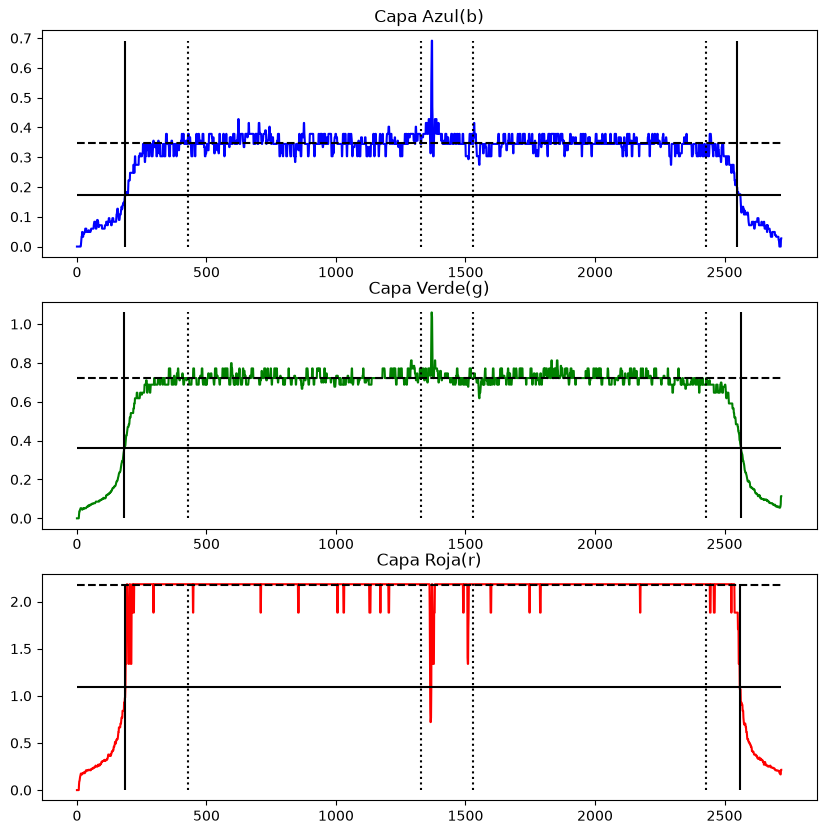

Media crossplane blue: 0.3487392784963893
Media crossplane green: 0.7241553254075261
Media crossplane red: 2.1780427652228935
HM crossplane blue: 0.17436963924819465
HM crossplane green: 0.36207766270376307
HM crossplane red: 1.0890213826114468


In [36]:
b_crossplane = placa_recorte_borde_b[
    centro_rotacion[1]
]

g_crossplane = placa_recorte_borde_g[
    centro_rotacion[1]
]

r_crossplane= placa_recorte_borde_r[
    centro_rotacion[1]
]

b_crossplane = filtro_mediana(b_crossplane)
g_crossplane = filtro_mediana(g_crossplane)
r_crossplane = filtro_mediana(r_crossplane)

# Ese es el array del corte crossplane, crudo. No se debe modificar mas
# hay que es hacer el analisis a partir de estos datos

media_crossplane_b = (np.mean(
    b_crossplane[
        centro_rotacion[1] - extremo_meseta
        :
        centro_rotacion[1] - excepcion_centro
        ]) + np.mean(b_crossplane[
            centro_rotacion[1] + excepcion_centro
            :
            centro_rotacion[1] + extremo_meseta
            ])
) * 0.5

media_crossplane_g = (np.mean(
    g_crossplane[
        centro_rotacion[1] - extremo_meseta
        :
        centro_rotacion[1] - excepcion_centro
        ]) + np.mean(g_crossplane[
            centro_rotacion[1] + excepcion_centro
            :
            centro_rotacion[1] + extremo_meseta
            ])
) * 0.5

media_crossplane_r = (np.mean(
        r_crossplane[
            centro_rotacion[1] - extremo_meseta
            :
            centro_rotacion[1] - excepcion_centro
            ]) + np.mean(r_crossplane[
                centro_rotacion[1] + excepcion_centro
                :
                centro_rotacion[1] + extremo_meseta
                ])
) * 0.5

HM_crossplane_b = 0.5 * (media_crossplane_b + np.min(b_crossplane))
HM_crossplane_g = 0.5 * (media_crossplane_g + np.min(g_crossplane))
HM_crossplane_r = 0.5 * (media_crossplane_r + np.min(r_crossplane))

# Cortes crossplane blue
corte_1c_b = encontrar_interseccion_HM(
    b_crossplane[:centro_rotacion[1] - extremo_meseta],
    HM_crossplane_b
)

corte_2c_b = encontrar_interseccion_HM(
    b_crossplane[centro_rotacion[1] + extremo_meseta:],
    HM_crossplane_b
) + extremo_meseta + centro_rotacion[1]

# Cortes crossplane green
corte_1c_g = encontrar_interseccion_HM(
    g_crossplane[:centro_rotacion[1] - extremo_meseta],
    HM_crossplane_g
)

corte_2c_g = encontrar_interseccion_HM(
    g_crossplane[centro_rotacion[1] + extremo_meseta:],
    HM_crossplane_g
) + extremo_meseta + centro_rotacion[1]

# Cortes crossplane red
corte_1c_r = encontrar_interseccion_HM(
    r_crossplane[:centro_rotacion[1] - extremo_meseta],
    HM_crossplane_r
)

corte_2c_r = encontrar_interseccion_HM(
    r_crossplane[centro_rotacion[1] + extremo_meseta:],
    HM_crossplane_r
) + extremo_meseta + centro_rotacion[1]


plt.figure(figsize = (10, 10))

plt.subplot(3, 1, 1)
plt.plot(b_crossplane, color = 'blue')

plt.vlines(centro_rotacion[1] - extremo_meseta, np.min(b_crossplane),
           np.max(b_crossplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[1] - excepcion_centro, np.min(b_crossplane),
           np.max(b_crossplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[1] + excepcion_centro, np.min(b_crossplane),
           np.max(b_crossplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[1] + extremo_meseta, np.min(b_crossplane),
           np.max(b_crossplane), colors = 'black', linestyles = ':')

# Corte a la altura media
plt.vlines(corte_1c_b, np.min(b_crossplane),
           np.max(b_crossplane), colors = 'black', linestyles = '-')
plt.vlines(corte_2c_b, np.min(b_crossplane),
           np.max(b_crossplane), colors = 'black', linestyles = '-')

plt.hlines(media_crossplane_b, 0, np.shape(b_crossplane)[0], colors = 'black', linestyles = '--')
plt.hlines(HM_crossplane_b, 0, np.shape(b_crossplane)[0], colors = 'black', linestyles = '-')

plt.title('Capa Azul(b)')

plt.subplot(3, 1, 2)
plt.plot(g_crossplane, color = 'green')

plt.vlines(centro_rotacion[1] - extremo_meseta, np.min(g_crossplane),
           np.max(g_crossplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[1] - excepcion_centro, np.min(g_crossplane),
           np.max(g_crossplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[1] + excepcion_centro, np.min(g_crossplane),
           np.max(g_crossplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[1] + extremo_meseta, np.min(g_crossplane),
           np.max(g_crossplane), colors = 'black', linestyles = ':')

# Corte a la altura media
plt.vlines(corte_1c_g, np.min(g_crossplane),
           np.max(g_crossplane), colors = 'black', linestyles = '-')
plt.vlines(corte_2c_g, np.min(g_crossplane),
           np.max(g_crossplane), colors = 'black', linestyles = '-')

plt.hlines(media_crossplane_g, 0, np.shape(g_crossplane)[0], colors = 'black', linestyles = '--')
plt.hlines(HM_crossplane_g, 0, np.shape(g_crossplane)[0], colors = 'black', linestyles = '-')

plt.title('Capa Verde(g)')

plt.subplot(3, 1, 3)
plt.plot(r_crossplane, color = 'red')

plt.vlines(centro_rotacion[1] - extremo_meseta, np.min(r_crossplane),
           np.max(r_crossplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[1] - excepcion_centro, np.min(r_crossplane),
           np.max(r_crossplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[1] + excepcion_centro, np.min(r_crossplane),
           np.max(r_crossplane), colors = 'black', linestyles = ':')
plt.vlines(centro_rotacion[1] + extremo_meseta, np.min(r_crossplane),
           np.max(r_crossplane), colors = 'black', linestyles = ':')

# Corte a la altura media
plt.vlines(corte_1c_r, np.min(r_crossplane),
           np.max(r_crossplane), colors = 'black', linestyles = '-')
plt.vlines(corte_2c_r, np.min(r_crossplane),
           np.max(r_crossplane), colors = 'black', linestyles = '-')

plt.hlines(media_crossplane_r, 0, np.shape(r_crossplane)[0], colors = 'black', linestyles = '--')
plt.hlines(HM_crossplane_r, 0, np.shape(r_crossplane)[0], colors = 'black', linestyles = '-')

plt.title('Capa Roja(r)')

plt.show()

print(f"Media crossplane blue: {media_crossplane_b}")
print(f"Media crossplane green: {media_crossplane_g}")
print(f"Media crossplane red: {media_crossplane_r}")

print(f"HM crossplane blue: {HM_crossplane_b}")
print(f"HM crossplane green: {HM_crossplane_g}")
print(f"HM crossplane red: {HM_crossplane_r}")

Depronto mejore la calidad del perfil y por tanto del analisis crear un umbral minimo para los perfiles, no, eso es recortar informacion que porta la placa solo para ajustar la curva al resultado ideal. 

Puede que no sea finalmente tan importante el recorte que sufren los perfiles por los limites fisicos de la superficie de la placa puesto que nuestro piso es confiable, y mientras nuestro piso sea el valor de la pelicula virgen solo importa tener el maximo y el punto donde corta a la media altura, por lo cual, no hay datos necesarios faltantes. A no ser de que se desee medir el ancho total de la penumbra o el area total bajo la curva o cosas que necesiten el perfil completo.

### FWHM Crossplane

Pero con la modificacion que hicimos de recortar el rango realmente estamos tomando el valor adecuado de pixel apra el calculo del FWHM? Pues parece que si, porque el grafico y los calculos los estamos haciendo es sobre el intervalo ya recortado, la diferencia no necesita posisicon absoluta, solo es la distancia, que es una cantidad de pixeles, entre un punto y otro de ese intervalo.

In [37]:
print(f"Posiciones corte blue(b):({corte_1c_b}, {corte_2c_b})")
print(f"Posiciones corte green(g):({corte_1c_g}, {corte_2c_g})")
print(f"Posiciones corte red(r):({corte_1c_r}, {corte_2c_r})")

Posiciones corte blue(b):(187, 2550)
Posiciones corte green(g):(183, 2563)
Posiciones corte red(r):(187, 2559)


In [38]:
FWHM_crossplane_b = (corte_2c_b - corte_1c_b) * tamano_pixel
FWHM_crossplane_g = (corte_2c_g - corte_1c_g) * tamano_pixel
FWHM_crossplane_r = (corte_2c_r - corte_1c_r) * tamano_pixel

print(f"FWHM blue(b): {np.round(FWHM_crossplane_b, 3)} mm")
print(f"FWHM Green(g): {np.round(FWHM_crossplane_g, 3)} mm")
print(f"FWHM Red(r): {np.round(FWHM_crossplane_r, 3)} mm")

FWHM blue(b): 100.034 mm
FWHM Green(g): 100.753 mm
FWHM Red(r): 100.415 mm


## Barrido en cada direccion

El barrido se va a hacer dentro del area que se selecciono para calcular la media, como para estandarizar todo el proceso pues.

### Barrido Inplane

In [39]:
delta_tol = 100 # mm
desviacion_tol = 0.025

ancho_barrido = 2 * extremo_meseta

Parece que realemnte es inproductivo hacer todo ese acondicionamiento de imagen para luego solo recortar todo por fuera de la curva con ese where, ahora que lo pienso esto... es mentir? Porque estor descartando datos que contiene la imagen solamente porque la curva no tiene la forma ideal que yo estoy esperando ver, entonces asi de peor, parece que el metodo correcto incluye medir la curva virgen sabiendo que ya habia garantizado el piso con los procesos de acondicionamiento de la imagen, donde se tapan los bordes. luego todo se vuelve igual aproximadamente a la pelicula virgen (Que creo ahora que se puede elegir facilmente de forma manual con un 6 punto marcado, lo cual puede aportar versatilidad) y luego volviendo esto el piso, lo cual es justamente lo que se espera sacar de la pelicula, recortar aun mas el piso para darle mejor forma a la curva parece un truco simplemente, a no ser de que lo que se este viendo en los perfiles sea ruido inducido por la forma de abrir y construir los perfiles, porque igual si es ruido que contiene la placa o el escaner, etc, entonces pues no es razon para modificar el codigo. 

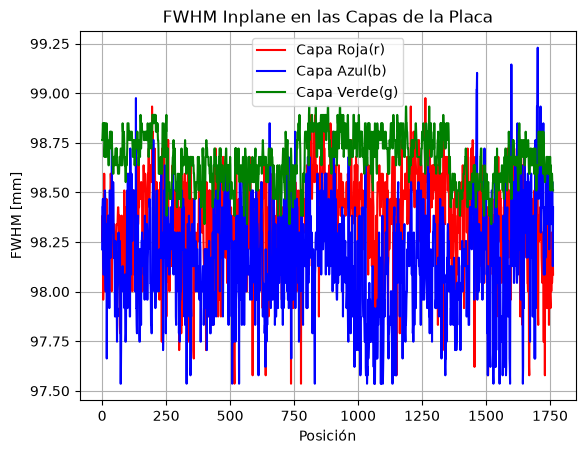

In [40]:
FWHM_ivals_b = []
FWHM_ivals_g = []
FWHM_ivals_r = []

for o in range(centro_rotacion[0] - ancho_barrido//2, centro_rotacion[0] + ancho_barrido//2):

    b_inplane_barrido = np.rot90(placa_recorte_borde_b)[
        np.shape(placa_recorte_borde_b)[1] - int(o)
    ]

    g_inplane_barrido = np.rot90(placa_recorte_borde_g)[
        np.shape(placa_recorte_borde_g)[1] - int(o)
    ]

    r_inplane_barrido = np.rot90(placa_recorte_borde_r)[
        np.shape(placa_recorte_borde_r)[1] - int(o)
    ]

    b_inplane_barrido = filtro_mediana(b_inplane_barrido)
    g_inplane_barrido = filtro_mediana(g_inplane_barrido)
    r_inplane_barrido = filtro_mediana(r_inplane_barrido)

    # Ese es el array del corte inplane, crudo. No se debe modificar mas
    # hay que es hacer el analisis a partir de estos datos

    media_inplane_b_barrido = (np.mean(
        b_inplane_barrido[
            centro_rotacion[0] - extremo_meseta
            :
            centro_rotacion[0] - excepcion_centro
            ]) + np.mean(b_inplane_barrido[
                centro_rotacion[0] + excepcion_centro
                :
                centro_rotacion[0] + extremo_meseta
                ])
    ) * 0.5

    media_inplane_g_barrido = (np.mean(
        g_inplane_barrido[
            centro_rotacion[0] - extremo_meseta
            :
            centro_rotacion[0] - excepcion_centro
            ]) + np.mean(g_inplane_barrido[
                centro_rotacion[0] + excepcion_centro
                :
                centro_rotacion[0] + extremo_meseta
                ])
    ) * 0.5

    media_inplane_r_barrido = (np.mean(
        r_inplane_barrido[
            centro_rotacion[0] - extremo_meseta
            :
            centro_rotacion[0] - excepcion_centro
            ]) + np.mean(r_inplane_barrido[
                centro_rotacion[0] + excepcion_centro
                :
                centro_rotacion[0] + extremo_meseta
                ])
    ) * 0.5

    HM_b_barrido = 0.5 * (media_inplane_b_barrido + np.min(b_inplane_barrido))
    HM_g_barrido = 0.5 * (media_inplane_g_barrido + np.min(g_inplane_barrido))
    HM_r_barrido = 0.5 * (media_inplane_r_barrido + np.min(r_inplane_barrido))

    # Cortes inplane blue
    corte_1i_b_barrido = encontrar_interseccion_HM(
        b_inplane_barrido[:centro_rotacion[0] - extremo_meseta],
        HM_b_barrido
    )

    corte_2i_b_barrido = encontrar_interseccion_HM(
        b_inplane_barrido[centro_rotacion[0] + extremo_meseta:],
        HM_b_barrido
    ) + extremo_meseta + centro_rotacion[0]

    # Cortes inplane green
    corte_1i_g_barrido = encontrar_interseccion_HM(
        g_inplane_barrido[:centro_rotacion[0] - extremo_meseta],
        HM_g_barrido
    )

    corte_2i_g_barrido = encontrar_interseccion_HM(
        g_inplane_barrido[centro_rotacion[0] + extremo_meseta:],
        HM_g_barrido
    ) + extremo_meseta + centro_rotacion[0]

    # Cortes inplane red
    corte_1i_r_barrido = encontrar_interseccion_HM(
        r_inplane_barrido[:centro_rotacion[0] - extremo_meseta],
        HM_r_barrido
    )

    corte_2i_r_barrido = encontrar_interseccion_HM(
        r_inplane_barrido[centro_rotacion[0] + extremo_meseta:],
        HM_r_barrido
    ) + extremo_meseta + centro_rotacion[0]

    FWHM_inplane_b_barrido = (corte_2i_b_barrido - corte_1i_b_barrido) * tamano_pixel
    FWHM_inplane_g_barrido = (corte_2i_g_barrido - corte_1i_g_barrido) * tamano_pixel
    FWHM_inplane_r_barrido = (corte_2i_r_barrido - corte_1i_r_barrido) * tamano_pixel

    # Tienen que ser los 3 array del mismo tamano?
    
    if (1 - desviacion_tol) * delta_tol <= FWHM_inplane_b_barrido <= delta_tol * (1 + desviacion_tol) and (1 - desviacion_tol) * delta_tol <= FWHM_inplane_g_barrido <= delta_tol * (1 + desviacion_tol) and (1 - desviacion_tol) * delta_tol <= FWHM_inplane_r_barrido <= delta_tol * (1 + desviacion_tol):

        FWHM_ivals_b.append(FWHM_inplane_b_barrido)
        FWHM_ivals_g.append(FWHM_inplane_g_barrido)
        FWHM_ivals_r.append(FWHM_inplane_r_barrido)


plt.plot(FWHM_ivals_r, color = 'red', label = 'Capa Roja(r)')
plt.plot(FWHM_ivals_b, color = 'blue', label = 'Capa Azul(b)')
plt.plot(FWHM_ivals_g, color = 'green', label = 'Capa Verde(g)')

plt.xlabel('Posición')
plt.ylabel('FWHM [mm]')
plt.title('FWHM Inplane en las Capas de la Placa')
plt.legend()
plt.grid()
plt.show()

In [41]:
print(f"Media barrido Azul(b) inplane: {np.mean(FWHM_ivals_b)} mm.")
print(f"Media barrido Verde(g) inplane: {np.mean(FWHM_ivals_g)} mm.")
print(f"Media barrido Rojo (r) inplane: {np.mean(FWHM_ivals_r)} mm.")

Media barrido Azul(b) inplane: 98.16718207600681 mm.
Media barrido Verde(g) inplane: 98.67143618831538 mm.
Media barrido Rojo (r) inplane: 98.38002533560218 mm.


### Barrido Crossplane

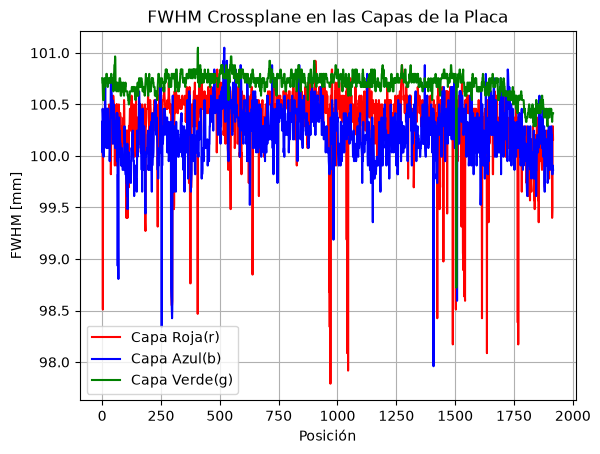

In [42]:
FWHM_cvals_b = []
FWHM_cvals_g = []
FWHM_cvals_r = []

for i in range(centro_rotacion[1] - ancho_barrido//2, centro_rotacion[1] + ancho_barrido//2):

    b_crossplane_barrido = placa_recorte_borde_b[
        int(i)
    ]

    g_crossplane_barrido = placa_recorte_borde_g[
        int(i)
    ]

    r_crossplane_barrido = placa_recorte_borde_r[
        int(i)
    ]

    b_crossplane_barrido = filtro_mediana(b_crossplane_barrido)
    g_crossplane_barrido = filtro_mediana(g_crossplane_barrido)
    r_crossplane_barrido = filtro_mediana(r_crossplane_barrido)

    # Ese es el array del corte inplane, crudo. No se debe modificar mas
    # hay que es hacer el analisis a partir de estos datos

    media_crossplane_b_barrido = (np.mean(
        b_crossplane_barrido[
            centro_rotacion[1] - extremo_meseta
            :
            centro_rotacion[1] - excepcion_centro
            ]) + np.mean(b_crossplane_barrido[
                centro_rotacion[1] + excepcion_centro
                :
                centro_rotacion[1] + extremo_meseta
                ])
    ) * 0.5

    HM_crossplane_b_barrido = 0.5 * (media_crossplane_b_barrido + np.min(b_crossplane_barrido))

    media_crossplane_g_barrido = (np.mean(
        g_crossplane_barrido[
            centro_rotacion[1] - extremo_meseta
            :
            centro_rotacion[1] - excepcion_centro
            ]) + np.mean(g_crossplane_barrido[
                centro_rotacion[1] + excepcion_centro
                :
                centro_rotacion[1] + extremo_meseta
                ])
    ) * 0.5

    HM_crossplane_g_barrido = 0.5 * (media_crossplane_g_barrido + np.min(g_crossplane_barrido))

    media_crossplane_r_barrido = (np.mean(
            r_crossplane_barrido[
                centro_rotacion[1] - extremo_meseta
                :
                centro_rotacion[1] - excepcion_centro
                ]) + np.mean(r_crossplane_barrido[
                    centro_rotacion[1] + excepcion_centro
                    :
                    centro_rotacion[1] + extremo_meseta
                    ])
    ) * 0.5

    HM_crossplane_r_barrido = 0.5 * (media_crossplane_r_barrido + np.min(r_crossplane_barrido))

    # Cortes inplane blue
    corte_1c_b_barrido = encontrar_interseccion_HM(
        b_crossplane_barrido[:centro_rotacion[1] - extremo_meseta],
        HM_crossplane_b_barrido
    )

    corte_2c_b_barrido = encontrar_interseccion_HM(
        b_crossplane_barrido[centro_rotacion[1] + extremo_meseta:],
        HM_crossplane_b_barrido
    ) + extremo_meseta + centro_rotacion[1]

    # Cortes inplane green
    corte_1c_g_barrido = encontrar_interseccion_HM(
        g_crossplane_barrido[:centro_rotacion[1] - extremo_meseta],
        HM_crossplane_g_barrido
    )

    corte_2c_g_barrido = encontrar_interseccion_HM(
        g_crossplane_barrido[centro_rotacion[1] + extremo_meseta:],
        HM_crossplane_g_barrido
    ) + extremo_meseta + centro_rotacion[1]

    # Cortes inplane red
    corte_1c_r_barrido = encontrar_interseccion_HM(
        r_crossplane_barrido[:centro_rotacion[1] - extremo_meseta],
        HM_crossplane_r_barrido
    )

    corte_2c_r_barrido = encontrar_interseccion_HM(
        r_crossplane_barrido[centro_rotacion[1] + extremo_meseta:],
        HM_crossplane_r_barrido
    ) + extremo_meseta + centro_rotacion[1]

    FWHM_crossplane_b_barrido = (corte_2c_b_barrido - corte_1c_b_barrido) * tamano_pixel
    FWHM_crossplane_g_barrido = (corte_2c_g_barrido - corte_1c_g_barrido) * tamano_pixel
    FWHM_crossplane_r_barrido = (corte_2c_r_barrido - corte_1c_r_barrido) * tamano_pixel

    # Tienen que ser los 3 array del mismo tamano?
    
    if (1 - desviacion_tol) * delta_tol <= FWHM_crossplane_b_barrido <= delta_tol * (1 + desviacion_tol) and (1 - desviacion_tol) * delta_tol <= FWHM_crossplane_g_barrido <= delta_tol * (1 + desviacion_tol) and (1 - desviacion_tol) * delta_tol <= FWHM_crossplane_r_barrido <= delta_tol * (1 + desviacion_tol):

        FWHM_cvals_b.append(FWHM_crossplane_b_barrido)
        FWHM_cvals_g.append(FWHM_crossplane_g_barrido)
        FWHM_cvals_r.append(FWHM_crossplane_r_barrido)

plt.plot(FWHM_cvals_r, color = 'red', label = 'Capa Roja(r)')

plt.plot(FWHM_cvals_b, color = 'blue', label = 'Capa Azul(b)')
plt.plot(FWHM_cvals_g, color = 'green', label = 'Capa Verde(g)')
plt.xlabel('Posición')
plt.ylabel('FWHM [mm]')
plt.title('FWHM Crossplane en las Capas de la Placa')
plt.legend()
plt.grid()
plt.show()

In [43]:
print(f"Media barrido Azul(b) crossplane: {np.mean(FWHM_cvals_b)} mm.")
print(f"Media barrido Verde(g) crossplane: {np.mean(FWHM_cvals_g)} mm.")
print(f"Media barrido Rojo (r) crossplane: {np.mean(FWHM_cvals_r)} mm.")

Media barrido Azul(b) crossplane: 100.2173540253869 mm.
Media barrido Verde(g) crossplane: 100.70229925230396 mm.
Media barrido Rojo (r) crossplane: 100.35970179099287 mm.


### Importante

Esta pasando algo que complica bastante el analisis a nivel general porque parece que los pisos de los 3 perfiles no coinciden. Cuando no aplico el rectangulo funciona superbien cuando no hay artefactos generados por los bordes, pero en zonas alejadas del centro, empiezan a aparecer, justamente porque se ve el fondo a traves de la imagen, esto logicamente se solucionar facil con generar el marco rectangular y dandole un valor igual al minimo de la penumbra, no se si el fallo ha sido que no se ha seleccionado adecuadamente ese valor, sino que esta cayendo en uno mucho mas bajo y por eso genera un piso tan inferior.

El resto del ajuste podria venir por simplemente definir el minimo valor diferente a cero.

## Coincidencia con el campo luminoso

Ahora simplemente debemos definir respecto al punto de FWHM como esta de alejado el punto por donde cruza la linea de campo luminoso trazada segun las esquinas.

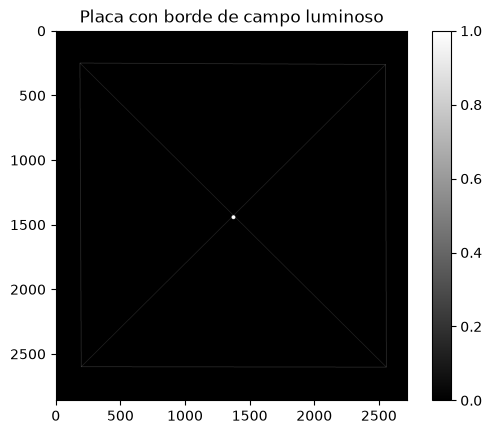

In [44]:
fondo_rotado = np.zeros(np.shape(placa_analizada_gray))

valor_trazos = 1
grosor_trazo = 1

cv2.line(fondo_rotado, punto_UL, punto_UR, valor_trazos, grosor_trazo)
cv2.line(fondo_rotado, punto_UL, punto_DL, valor_trazos, grosor_trazo)
cv2.line(fondo_rotado, punto_UL, punto_DR, valor_trazos, grosor_trazo)
cv2.line(fondo_rotado, punto_DL, punto_UR, valor_trazos, grosor_trazo)
cv2.line(fondo_rotado, punto_UR, punto_DR, valor_trazos, grosor_trazo)
cv2.line(fondo_rotado, punto_DL, punto_DR, valor_trazos, grosor_trazo)

# cv2.circle(fondo, (int(np.round(x_0, 0)), int(np.round(y_0, 0))), 15, color = 1, thickness = -1)
cv2.circle(fondo_rotado, punto_CC, 15, color = 1, thickness = -1)

plt.imshow(fondo_rotado, cmap = 'gray')
plt.title("Placa con borde de campo luminoso")
plt.colorbar()
plt.show()

Bueno, aqui simplemente hay que encontrar los puntos donde el trazado de las lineas de la imagen anterior tiene valores equivalentes a 1 que es el valor de la linea, de ancho 1, por lo cual para cada corte, identico al que se hace para cada perfil crossplane e inplane, restringiendo el centro pues debe haber un solo punto igual a 1 entre el extremo de la imagen y la frontera de exclusion del centro.

Pero ojo, ese grafico que usamos que es el primero del campo luminoso que construimos esta hecho con las coordenadas de las esquinas y el centro previas a la rotacion, y todo lo demas esta calculado a partir de la imagen ya rotada, por lo cual debemos construir nuevamente el plano del cuadrilatero.

In [45]:
LS = int(np.where(fondo_rotado[
    centro_rotacion[1]
][
    :
    np.shape(fondo_rotado)[0]//2 - extremo_meseta 
] == 1)[0][0])

RS = int(np.where(fondo_rotado[
    centro_rotacion[1]
][np.shape(fondo_rotado)[0]//2 + extremo_meseta
    :
] == 1)[0][0]) + np.shape(fondo_rotado)[0]//2 + extremo_meseta

US = int(np.where(np.rot90(fondo_rotado)[
    np.shape(fondo_rotado)[1] - centro_rotacion[0]
][
    :
    np.shape(fondo_rotado)[0]//2 - extremo_meseta 
] == 1)[0][0])

DS = int(np.where(np.rot90(fondo_rotado)[
    np.shape(fondo_rotado)[1] - centro_rotacion[0]
][np.shape(fondo_rotado)[0]//2 + extremo_meseta
    : 
] == 1)[0][0]) + np.shape(fondo_rotado)[0]//2 + extremo_meseta

desfase_Lb = LS - corte_1c_b
desfase_Lg = LS - corte_1c_g
desfase_Lr = LS - corte_1c_r

desfase_Rb = RS - corte_2c_b
desfase_Rg = RS - corte_2c_g
desfase_Rr = RS - corte_2c_r

desfase_Ub = US - corte_1i_b
desfase_Ug = US - corte_1i_g
desfase_Ur = US - corte_1i_r

desfase_Db = DS - corte_2i_b
desfase_Dg = DS - corte_2i_g
desfase_Dr = DS - corte_2i_r


print("Desfase placa Azul(b)")
print(f"Desfase Lado izquierdo: {np.round(desfase_Lb * tamano_pixel, 3)} mm")
print(f"Desfase lado derecho: {np.round(desfase_Rb * tamano_pixel, 3)} mm")
print(f"Desfase lado superior: {np.round(desfase_Ub * tamano_pixel, 3)} mm")
print(f"Desfase lado inferior: {np.round(desfase_Db * tamano_pixel, 3)} mm")

print("Desfase placa Verde(g)")
print(f"Desfase Lado izquierdo: {np.round(desfase_Lg * tamano_pixel, 3)} mm")
print(f"Desfase lado derecho: {np.round(desfase_Rg * tamano_pixel, 3)} mm")
print(f"Desfase lado superior: {np.round(desfase_Ug * tamano_pixel, 3)} mm")
print(f"Desfase lado inferior: {np.round(desfase_Dg * tamano_pixel, 3)} mm")

print("Desfase placa Rojo(r)")
print(f"Desfase Lado izquierdo: {np.round(desfase_Lr * tamano_pixel, 3)} mm")
print(f"Desfase lado derecho: {np.round(desfase_Rr * tamano_pixel, 3)} mm")
print(f"Desfase lado superior: {np.round(desfase_Ur * tamano_pixel, 3)} mm")
print(f"Desfase lado inferior: {np.round(desfase_Dr * tamano_pixel, 3)} mm")

Desfase placa Azul(b)
Desfase Lado izquierdo: 0.212 mm
Desfase lado derecho: 0.212 mm
Desfase lado superior: 0.508 mm
Desfase lado inferior: 1.651 mm
Desfase placa Verde(g)
Desfase Lado izquierdo: 0.381 mm
Desfase lado derecho: -0.339 mm
Desfase lado superior: 1.101 mm
Desfase lado inferior: 1.482 mm
Desfase placa Rojo(r)
Desfase Lado izquierdo: 0.212 mm
Desfase lado derecho: -0.169 mm
Desfase lado superior: 0.889 mm
Desfase lado inferior: 1.651 mm


## Cuadratura del campo luminoso

Aqui trataremos de reportar resultados de un analisis para cuantificar de forma simple que tan cuadrado es el campo luminoso trazado por los 4 puntos marcados, realmente aqui no importa tanto si se parte de la imagen rotada o no , solamente que tan cuadrado es, particularmente:

- Que tan largo es cada lado.
- Que inclinacion tiene cada lado respecto a su eje correspondiente (Horizontal o vertical).

In [46]:
l_left = punto_DL[1] - punto_UL[1] 
l_right = punto_DR[1] - punto_UR[1]
l_up = punto_UR[0] - punto_UL[0]
l_down = punto_DR[0] - punto_DL[0]

tetha_left =  np.degrees(np.arctan((punto_UL[0] - punto_DL[0])/(punto_UL[1] - punto_DL[1])))
tetha_right =  np.degrees(np.arctan((punto_UR[0] - punto_DR[0])/(punto_UR[1] - punto_DR[1])))
tetha_up =  np.degrees(np.arctan((punto_UL[1] - punto_UR[1])/(punto_UR[0] - punto_UL[0])))
tetha_down =  np.degrees(np.arctan((punto_DL[1] - punto_DR[1])/(punto_DR[0] - punto_DL[0])))


print(f"Angulo izq: {tetha_left}")
print(f"Angulo der: {tetha_right}")
print(f"Angulo arr: {np.round(tetha_up, 3)}")
print(f"Angulo aba: {np.round(tetha_down, 3)}")

print(f"Longitud lado izquierdo: {np.round(l_left * tamano_pixel, 3)} mm")
print(f"Longitud lado derecho: {np.round(l_right * tamano_pixel, 3)} mm")
print(f"Longitud lado superior: {np.round(l_up * tamano_pixel, 3)} mm")
print(f"Longitud lado inferior: {np.round(l_down * tamano_pixel, 3)} mm")

Angulo izq: 0.24381035610408464
Angulo der: 0.14678647522266564
Angulo arr: -0.266
Angulo aba: -0.073
Longitud lado izquierdo: 99.483 mm
Longitud lado derecho: 99.145 mm
Longitud lado superior: 100.118 mm
Longitud lado inferior: 99.949 mm


Pero para reportar el angulo debemos considerar el angulo rotado? No si este es buena referencia, pero no podemos simplemente operar con el porque, entonces en base a que estamos midiendo esos angulos que reportamos. Deberiamos es enderezar uno de los lados y apartir de ese medir los demas., Lo cual deberia ser equivalente a enderezar una de las diagonales y medir los demas angulos respecto a esta, cual elegimos? Pues la de mayor angulo, para que la rotacion tenga mayor impacto y esta va a ser nuestra referencia.

## Curvas de OD vs Dosis [cGy]

Ahora vamos a ajustar una funcion polinomica al conjunto de datos que indican la dosis para cada imagen, para esto debemos primero extraer la densidad optica y emparejarla con la dosis, ya tendriamos nuestro conjunto de datos y ya luego se puede hacer el ajuste con la funcion racional de Devic.

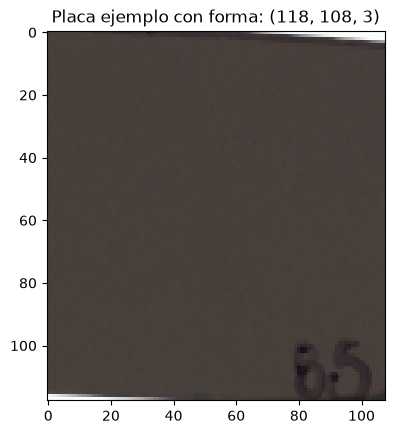

In [47]:
# '/home/felipepp/Documents/CodigosPython/ImagenesDeReferencia/Calibracion/1000.tif'

placa_ejemplo = cv2.imread(
    '/home/felipepp/Documents/CodigosPython/ImagenesDeReferencia/Calibracion/1000.tif',
    1
)

plt.imshow(placa_ejemplo, cmap = 'jet')
plt.title(f"Placa ejemplo con forma: {np.shape(placa_ejemplo)}")
plt.show()

In [48]:
b_e, g_e, r_e = cv2.split(placa_ejemplo)

b_e = np.where(
    b_e <= 0,
    1,
    b_e
)

r_e = np.where(
    r_e <= 0,
    1,
    r_e
)

g_e = np.where(
    g_e <= 0,
    1,
    g_e
)

placa_ejemplo_g = np.log10(
    valor_pelicula_g
    /
    np.where(
        g_e >= valor_pelicula_g,
        valor_pelicula_g,
        g_e
    )
)


In [49]:
def extraer_OD(placa_dosis_x, flag_capa_color):

    forma_x = np.shape(placa_dosis_x)

    b_p, g_p, r_p = cv2.split(placa_dosis_x)

    if flag_capa_color == 0:

        OD_b = np.mean(np.log10(
            valor_pelicula_b
            /
            np.where(
                b_p >= valor_pelicula_b,
                valor_pelicula_b,
                b_p
            )[
                forma_x[0]//2 - 20 : forma_x[1]//2 + 20,
                forma_x[0]//2 - 20 : forma_x[1]//2 + 20
            ]
        ))

        return OD_b

    elif flag_capa_color == 1:

        OD_g = np.mean(np.log10(
            valor_pelicula_g
            /
            np.where(
                g_p >= valor_pelicula_g,
                valor_pelicula_g,
                g_p
            )[
                forma_x[0]//2 - 20 : forma_x[1]//2 + 20,
                forma_x[0]//2 - 20 : forma_x[1]//2 + 20
            ]
        ))

        net_OD_g = np.mean(OD_g)

        return net_OD_g

    elif flag_capa_color == 2:

        OD_r = np.mean(np.log10(
            valor_pelicula_r
            /
            np.where(
                r_p >= valor_pelicula_r,
                valor_pelicula_r,
                r_p
            )[
                forma_x[0]//2 - 20 : forma_x[1]//2 + 20,
                forma_x[0]//2 - 20 : forma_x[1]//2 + 20
            ]
        ))

        return OD_r

    else:

        None

Parece que no hay que restarle el valor medio de la pelicula virgen si ya hacemos la normalizacion con el funcion where, pues tira al piso todo de una vez.

In [50]:
lista_ODnet = []
lista_Dosis_cGy = []

lista_ODnet.append(
    float(extraer_OD(
        cv2.imread(
            '/home/felipepp/Documents/CodigosPython/ImagenesDeReferencia/Calibracion/5.tif',
            1
        ),
        1
    ))
)

lista_Dosis_cGy.append(5)

for i in range(50, 1050, 50):

    lista_Dosis_cGy.append(int(i))

    ruta = '/home/felipepp/Documents/CodigosPython/ImagenesDeReferencia/Calibracion/' + str(i) + '.tif'

    imagen = cv2.imread(ruta, 1)
    lista_ODnet.append(float(extraer_OD(imagen, 1)))

In [51]:
np.array(lista_ODnet)

array([0.11172114, 0.15035717, 0.18094489, 0.21084286, 0.2398903 ,
       0.26352521, 0.2868482 , 0.30967824, 0.32411668, 0.34501838,
       0.35877606, 0.37302544, 0.38907365, 0.40762696, 0.41702562,
       0.43095152, 0.44292489, 0.45698923, 0.47085253, 0.48410755,
       0.49266968])

In [52]:
np.array(lista_Dosis_cGy) / 100

array([ 0.05,  0.5 ,  1.  ,  1.5 ,  2.  ,  2.5 ,  3.  ,  3.5 ,  4.  ,
        4.5 ,  5.  ,  5.5 ,  6.  ,  6.5 ,  7.  ,  7.5 ,  8.  ,  8.5 ,
        9.  ,  9.5 , 10.  ])

1.0347426905414963e-14 48.71517294992727 2.23227552828105


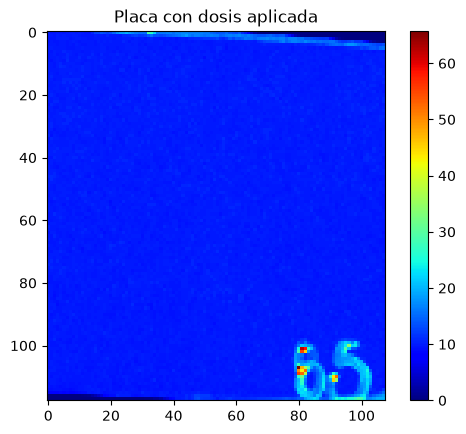

In [53]:
from scipy.optimize import curve_fit

def modelo_dosis(net_OD, a, b, c):
    return a * net_OD + b * (net_OD ** c)

array_netOD = np.array(lista_ODnet)
array_Dosis_cGy = np.array(lista_Dosis_cGy) / 100

limites_inferiores = [0.0, 0.0, 0.0]
limites_superiores = [10000.0, 10000.0, 3.0]

popt, _ = curve_fit(
    modelo_dosis, 
    array_netOD,
    array_Dosis_cGy,
    p0 = [5.0, 10.0, 1.8],
    bounds = (limites_inferiores, limites_superiores),
    maxfev = 10000,
    method = "trf"
)
a_fit, b_fit, c_fit = popt

imagen_dosis_g = modelo_dosis(placa_ejemplo_g, a_fit, b_fit, c_fit)

print(a_fit, b_fit, c_fit)

plt.imshow(imagen_dosis_g, cmap = 'jet')
plt.title('Placa con dosis aplicada')
plt.colorbar()
plt.show()

In [54]:
print(
    f"Dosis [Gy] centro de la placa = {
        np.round(
            imagen_dosis_g[np.shape(imagen_dosis_g)[1]//2][np.shape(imagen_dosis_g)[0]//2],
            3
    )} Gy"
)

Dosis [Gy] centro de la placa = 9.947 Gy


No olvidar que luego de ajustar la curva, que es simplemente tener los coeficientes calculados preferiblemente en el rango esperado pues se debe es alimenta la funcion con la densidad optica neta y con con los coeficientes, no con la dosis. Ya se que calculemos primero la densidad optica del fondo, luego la densidad optica de la pelicula virgen, luego la densidad optica de la capa verde con la referencia de intensidad del fondo de 255 y luego hagamos la resta para hayar la densidad optica neta, obtenemos el mismo resultado que si simplemente calculamos la densidad optica segun la razon entre el nivel de intensidad de la pelicula virgen respecto al nivel de intensidad de la capa de color correspondiente, que es lo que ya estamos haciendo y por eso es tambien una densidad optica neta.

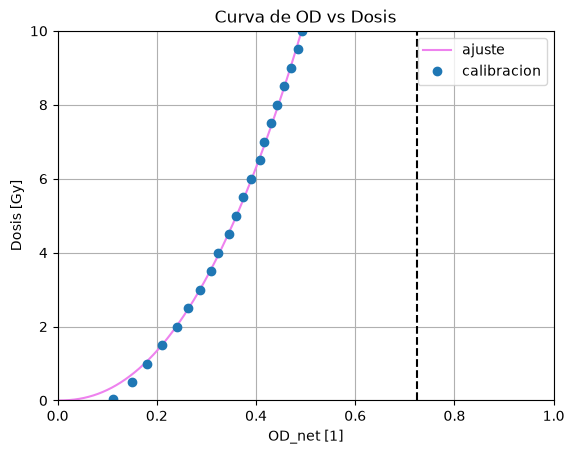

In [55]:
x_OD = np.linspace(0, array_netOD.max(), 2000)

plt.plot(x_OD, modelo_dosis(x_OD, *popt), color = 'violet', label = 'ajuste') # Debo alimentar con el eje x y el eje y
plt.plot(array_netOD, array_Dosis_cGy, 'o', label = 'calibracion')
plt.title('Curva de OD vs Dosis')
plt.xlabel('OD_net [1]')
plt.ylabel('Dosis [Gy]')
plt.xlim((0, 1))
plt.ylim((0, np.max(array_Dosis_cGy)))
plt.grid()
plt.legend()

plt.vlines(media_crossplane_g, 0, np.max(array_Dosis_cGy), colors = 'Black', linestyles = '--')

plt.show()

Aqui hay algo problematico y es que no tenemos el rango que representa la imagen de la capa verde de 0.7 en densidad optica cubierto por el rango de la calibracion, por lo cual no hay certeza de que el ajuste sea correcto y por la forma de la curva asumimos que simplemente se dispara. Esto puede ser una de las razones por la que la dosis de la meseta alcanza segun este analisis 23 Gy de media. Tambien cabe la posibilidad de que la densidad optica calculada sea incorrecta. La ultima posible opcion es que simplemente la dosis que esta alcanzando es correcta y que realemente no se le estan dando 800 UM a 1 cGy/UM.


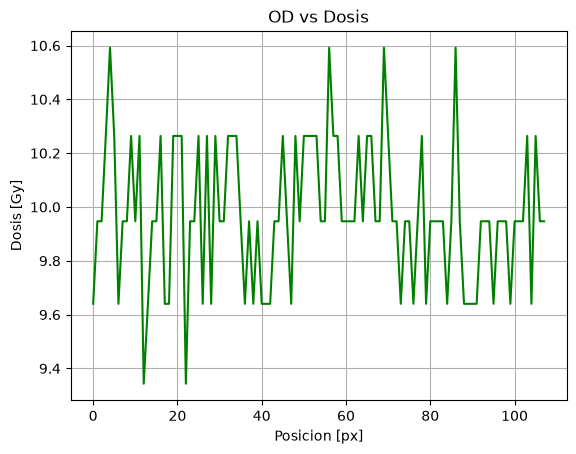

In [56]:
crossplane_g_dosis = imagen_dosis_g[   
    np.shape(imagen_dosis_g)[0]//2
]

plt.plot(crossplane_g_dosis, color = 'green')
plt.title('OD vs Dosis')
plt.xlabel('Posicion [px]')
plt.ylabel('Dosis [Gy]')
plt.grid()
plt.show()

### Justificacion

Bueno, resulta que el analisis de estas placas no se debe hacer con los perfiles de intensidad crudos, pues por las propiedades fisicas del paso de fotones por un material, las interacciones que este experimenta hacen que varie el paso de particulas logarimicamente, puesto que cada fraccion del material absorbe o interactua con los fotones, y el efecto se acumula segun el espesor del material, por esto tambien es importante hacer las pruebas de calibracion para cada lote pues su espesor puede cambiar ligeramente, afectando fuertemente el paso de luz resultante para la misma dosis recibida, ademas el tema es que lo que nosotros vemos es intensidad de luz, y el efecto que produce la radiacion sobre la pelicula es un efecto de polimerizacion, estas dos se relacionan directamente por el paso total de fotones a traves del material, partiendo de nuestra pelicula virgen como referencia o piso de intensidad optica. Una vez tenemos realmente cual es la opacidad resultante de la pelicula, usamos la curva ajustada a las peliculas de calibracion para encontrar la dosis correspondiente a al mapa de densidad optica de la placa analizada. Es importante recordar que los mapas de cada capa de color son originalmente valles, es decir, los maximos se encuentran en las periferias, porque lo que indican es la intensidad de luz, logicamente si se vuelve mas opaca la pelicula en el centro es por donde menos luz pasa. Ahora bien, cuando hacemos la conversion a densidad optica lo que resulta es el perfil con su geometria invertida, pues la densidad optica habla es tal cual de que tan opaco es el medio, y lo es justamente por donde menos luz pasa. Asi que solo por la aplicacion de los principios fisicos el perfil se invierte automaticamente, y como este si es directamente proporcional a la dosis, permanece en la misma orientacion, supongo que la polimerizacion de la pelicula no es lineal como vemos en las curvas de calibracion, puesto que entra en juego la penetracion y la saturacion, fenomenos que no varian linealmente, y que generan un aplanado en la curva, lo que significa que la densidad optica deja de aumentar mientras la dosis sigue aumentando, por lo que a dosis altas es muy inestable la medicion.

## Problema

Vemos que la calibracion genera un resultado euivalente a una dosis muy alta, este resultado primero no es confiable porque la curva de ajuste no presenta un aplanado sino que crece de forma monotona exponencialmente, lo cu

### Para revisar con Claude lo siguiente:

- Es mejor y posible hacer todo esto con una imagen em formaoto .TIF?
- Si se aplica la descomposicion por colores con cv2.split() en b, g y r? En ese orden?
- El zoom esta muy profundo en la app, prefeririria que se viera el perfil completo.
- He visto por ahi que dependiendo de la dosis se le debe crear mas a una capa de color que a otra, entre la roja y la verde, Adriana me dice que normalmente son menos de 10 Grey, como 6 Gy, igual lo que quiero es simplemente mostrar los 3 y toda la inforamcion disponible, incluso la media de los barridos, pero solo para confirmar Claude que sabe de esto y como se refleja esto en cada perfil para saber si estoy obteniendo algo parecido a lo que deberia dar.
- Cual es el signo correcto del angulo que se debe poner y por que?

Nuevas:
- Medir tambien el ancho de la penumbra, se que no es posible si la placa no tiene el tamano suficiente pero dejarlo implementado y reportar el ancho, se puede igual establecer un aviso que junto con el perfil completo informan si los perfiles se encuentran recortados y si ese ancho medido esta incompleto.
- Garantizamos entonces los perfiles crossplane e inplane completos, su FWHM y todas las medidas necesarias para incluirlo con las zonas de interes etc, la forma, tamano y cuadratura de los campos luminosos, el desfase por lado del campo de radiacion frente al campo luminoso y las mediciones de la penumbra.

En braqui mostrar con un zoom mas alejado o casi completo los perfiles por color.